In [11]:
%pip install qiskit qiskit-aer matplotlib

import qiskit
import qiskit_aer
import numpy as np
print("Qiskit:", qiskit.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)
print("NumPy:", np.__version__)

Note: you may need to restart the kernel to use updated packages.
Qiskit: 2.2.3
Qiskit Aer: 0.17.2
NumPy: 1.22.3


               ┌───┐          ┌─┐                      
q_0: ──■────■──┤ I ├──■───────┤M├──────────────────────
     ┌─┴─┐  │  ├───┤  │       └╥┘             ┌─┐      
q_1: ┤ X ├──┼──┤ I ├──┼────■───╫───■──────────┤M├──────
     └───┘┌─┴─┐├───┤  │    │   ║   │          └╥┘   ┌─┐
q_2: ─────┤ X ├┤ I ├──┼────┼───╫───┼───────■───╫────┤M├
          └───┘└───┘┌─┴─┐┌─┴─┐ ║   │  ┌─┐  │   ║    └╥┘
q_3: ───────────────┤ X ├┤ X ├─╫───┼──┤M├──┼───╫─────╫─
                    └───┘└───┘ ║ ┌─┴─┐└╥┘┌─┴─┐ ║ ┌─┐ ║ 
q_4: ──────────────────────────╫─┤ X ├─╫─┤ X ├─╫─┤M├─╫─
                               ║ └───┘ ║ └───┘ ║ └╥┘ ║ 
c: 5/══════════════════════════╩═══════╩═══════╩══╩══╩═
                               0       3       1  4  2 
p=0.01 | Simulated=0.0002 | Theory=0.0003
               ┌───┐          ┌─┐                      
q_0: ──■────■──┤ I ├──■───────┤M├──────────────────────
     ┌─┴─┐  │  ├───┤  │       └╥┘             ┌─┐      
q_1: ┤ X ├──┼──┤ I ├──┼────■───╫───■──────────┤M├──────
     └

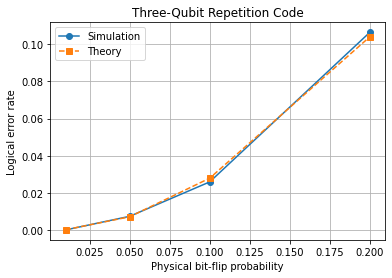

In [12]:

import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, pauli_error


# 1. Build the three-qubit repetition code
def build_circuit(bit=0):
    qc = QuantumCircuit(5, 5)

    # Encode the logical bit
    if bit == 1:
        qc.x(0)

    qc.cx(0, 1)
    qc.cx(0, 2)

    # Noise is applied after these identity gates
    for q in range(3):
        qc.id(q)

    # Measure error syndromes
    qc.cx(0, 3)
    qc.cx(1, 3)
    qc.cx(1, 4)
    qc.cx(2, 4)

    qc.measure(3, 3)
    qc.measure(4, 4)
    qc.measure([0, 1, 2], [0, 1, 2])
    print(qc)

    return qc


# 2. Add random bit-flip noise
def make_noise(p):
    noise = NoiseModel()
    error = pauli_error([("X", p), ("I", 1 - p)])
    noise.add_all_qubit_quantum_error(error, ["id"])
    return noise


# 3. Decode the syndrome
def decode(s0, s1):
    return {(0, 0): None, (1, 0): 0,
            (1, 1): 1, (0, 1): 2}[(s0, s1)]


# 4. Estimate the logical error rate
def logical_error_rate(p, shots=10_000, bit=0):
    qc = build_circuit(bit)
    sim = AerSimulator(noise_model=make_noise(p))
    counts = sim.run(qc, shots=shots).result().get_counts()

    failures = 0

    for key, count in counts.items():
        b = key[::-1]

        data = [int(b[i]) for i in range(3)]
        s0, s1 = int(b[3]), int(b[4])

        error_qubit = decode(s0, s1)

        if error_qubit is not None:
            data[error_qubit] ^= 1

        decoded_bit = int(sum(data) >= 2)

        if decoded_bit != bit:
            failures += count

    return failures / shots


# 5. Run the experiment
probabilities = [0.01, 0.05, 0.10, 0.20]
results = []

for p in probabilities:
    simulated = logical_error_rate(p)
    theory = 3 * p**2 - 2 * p**3

    results.append(simulated)

    print(
        f"p={p:.2f} | "
        f"Simulated={simulated:.4f} | "
        f"Theory={theory:.4f}"
    )


# 6. Plot the results
plt.plot(probabilities, results, "o-", label="Simulation")
plt.plot(
    probabilities,
    [3*p**2 - 2*p**3 for p in probabilities],
    "s--",
    label="Theory"
)

plt.xlabel("Physical bit-flip probability")
plt.ylabel("Logical error rate")
plt.title("Three-Qubit Repetition Code")
plt.legend()
plt.grid(True)
plt.show()
